# Cedar | 2D OPFData Hessian reconstruction

This is the **current Algorithm 1 implementation**, using a fitted CART regression tree on a 5,000-row OPFData IEEE-118 subset. Cost is CSV column 0; the selected predictors are CSV columns 1–2. All calculations use the original data values.

The purpose is to compare (a) the symmetrized tree-derived estimate and (b) residual-based Principal Hessian Directions (PHD), and to examine the unsymmetrized row estimates **before** enforcing symmetry.

**Reader's guide.** The code is intentionally short. The notebooks retain **executed numerical output blocks and three embedded historical diagnostic figures**. Those figures use the same raw CART/PHD estimates as the current code. The final symmetrized matrix is displayed separately. Neither estimator is the known physical OPF Hessian.

## 1. Algorithm 1: from tree splits to a Hessian

For a general quadratic response,

$$
f(x)=c+b^\top x+\frac12 x^\top Qx,\qquad Q=Q^\top.
$$

At each internal CART node $A$, read split feature $s_A$, threshold $\tau_A$, rectangular bounds $\ell_A,u_A$, and the **empirical mean responses of its left and right children** $\mu_L^A,\mu_R^A$. Define

$$
\gamma_A=\frac{2(\mu_R^A-\mu_L^A)}{u_{A,s_A}-\ell_{A,s_A}}.
$$

The effective location implied by the *uniform regional-average quadratic derivation* is

$$
z_{A,k}=
\begin{cases}
(\ell_{A,s_A}+\tau_A+u_{A,s_A})/3,&k=s_A,\\
(\ell_{A,k}+u_{A,k})/2,&k\ne s_A.
\end{cases}
$$

Compare **all distinct internal-node pairs** $(A,B)$ with the same split feature $s=s_A=s_B$ and unequal effective locations:

$$
V_s[A,B,:]=(z_B-z_A)^\top,\qquad
y_s[A,B]=\gamma_B-\gamma_A.
$$

When any $\operatorname{rank}(V_s)<d$, return **not identified**. Otherwise solve $V_sq_s\approx y_s$ by ordinary least squares for every row. The **reported output** is

$$
\boxed{\widehat Q=\frac12\left(\widetilde Q+\widetilde Q^\top\right),}
$$

where row $s$ of $\widetilde Q$ is $q_s^\top$. We retain $\widetilde Q$ separately to measure the raw row disagreement. The shared implementation is in \`algorithm1_tree_hessian.py\` and is also used by the 2D quadratic Colab example.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from algorithm1_tree_hessian import estimate_tree_hessian

# If running elsewhere, edit or place the CSV at one of these paths.
CSV_PATH = next((p for p in [Path('/mnt/data/118_ieee_smol.csv'),
    Path('/Users/tonys/Desktop/Class/Decision Trees/datasets/118_ieee_smol.csv'),
    Path('/content/drive/MyDrive/118_ieee_smol.csv'), Path('118_ieee_smol.csv')]
    if p.exists()), None)
if CSV_PATH is None:
    raise FileNotFoundError('Set CSV_PATH to 118_ieee_smol.csv')

D = 2
frame = pd.read_csv(CSV_PATH, header=None, usecols=range(D + 1))
y, X = frame.iloc[:, 0].to_numpy(float), frame.iloc[:, 1:].to_numpy(float)
print(f'{len(y)} observations, {D} selected demands; columns 1...{D}')


5000 observations, 2 selected demands; columns 1...2


## 2. Residual-based PHD comparison

Let $z_i=x_i-\bar x$ and let $r_i$ be the ordinary linear-regression residual after fitting $y$ to an intercept and the selected predictors. With

$$
\widehat\Sigma=\frac1n\sum_{i=1}^n z_i z_i^\top,
$$

the residual-based PHD matrix is

$$
\widehat Q_{\mathrm{PHD}}
=\widehat\Sigma^{-1}
\left(\frac1n\sum_{i=1}^n r_i z_i z_i^\top\right)
\widehat\Sigma^{-1}.
$$

PHD is symmetric by construction (up to floating-point error), but its average-Hessian interpretation requires distributional assumptions, notably Gaussian predictors, which are **not established for this dataset**.

## 3. Executed numerical estimates

The following code displays the **final symmetrized Algorithm 1 estimate**, the raw row matrix, and PHD in their original units. A full-rank design makes each row algebraically identifiable, **not statistically accurate**.

The exact matrix values are saved as notebook outputs, not just described in text.

In [2]:
def phd(X, y):
    """Residual-based PHD; not a known true Hessian on OPFData."""
    z = X - X.mean(0)
    D = np.c_[np.ones(len(y)), z]
    r = y - D @ np.linalg.lstsq(D, y, rcond=None)[0]
    S, M = z.T @ z / len(y), z.T @ (r[:, None] * z) / len(y)
    A = np.linalg.solve(S, M)
    H = np.linalg.solve(S, A.T).T
    return (H + H.T) / 2

tree = DecisionTreeRegressor(max_depth=7, random_state=0).fit(X, y)
Qhat, Qraw, diagnostics = estimate_tree_hessian(tree, X)
if Qhat is None:
    raise ValueError(f'Algorithm 1: not identified. Rows: {diagnostics}')
Hphd = phd(X, y)
print('Rows (axis, internal nodes, pairs, rank):', diagnostics)
print('Tree raw rows:\n', np.round(Qraw, 2))
print('Algorithm 1 final symmetric Hessian:\n', np.round(Qhat, 2))
print('Residual PHD matrix:\n', np.round(Hphd, 2))
print('Raw asymmetry max:', round(np.max(abs(Qraw-Qraw.T)), 2))


Rows (axis, internal nodes, pairs, rank): [(1, 67, 2211, 2), (2, 59, 1711, 2)]
Tree raw rows:
 [[  210716.98  -733998.62]
 [-3154084.83 -3905774.69]]
Algorithm 1 final symmetric Hessian:
 [[  210716.98 -1944041.73]
 [-1944041.73 -3905774.69]]
Residual PHD matrix:
 [[ 140086.44 -474727.79]
 [-474727.79  830031.37]]
Raw asymmetry max: 2420086.2


## 4. Historical-style diagnostic figures

The three figures below reproduce the earlier visual comparisons using the same numeric raw CART and PHD estimates: **PHD**, **raw tree row estimates**, and **absolute symmetry discrepancies**. Colors are scaled in millions only to make the labels readable. They are stored in the notebook so GitHub can render them without executing Python.

The final symmetrized Algorithm 1 matrix is shown in the numerical output above. Its off-diagonal values average the corresponding raw entries; symmetrization cannot resolve the underlying estimation error.

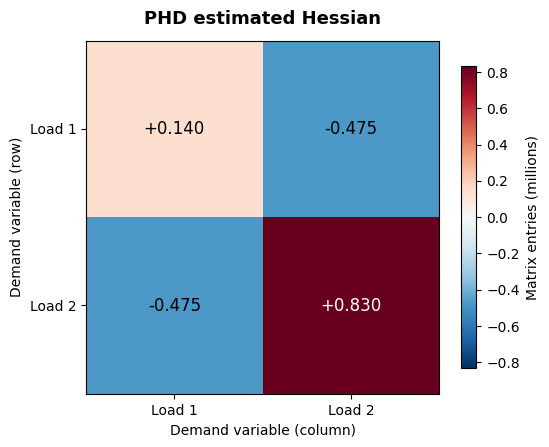

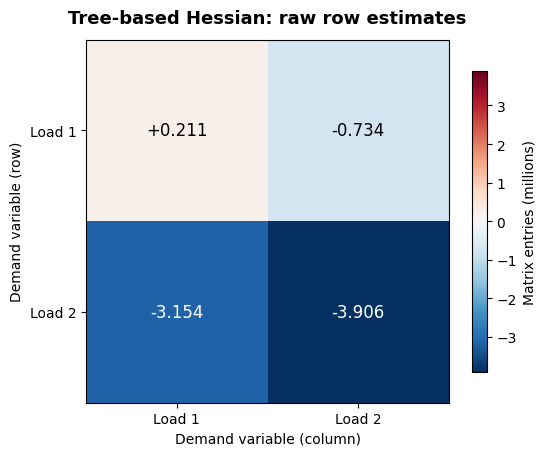

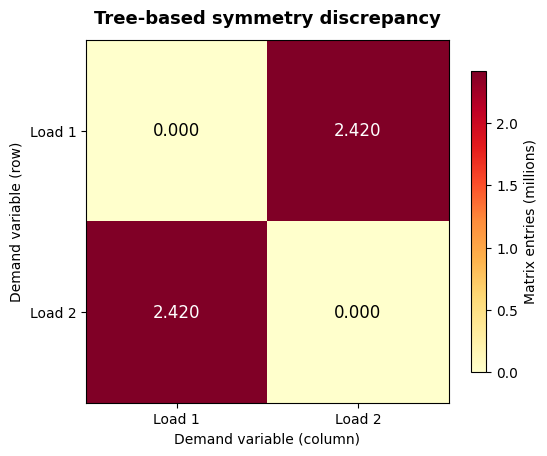

In [3]:
H_tree_raw, H_phd = Qraw, Hphd  # aliases for the preserved diagnostic plotting routine
def plot_hessian(matrix: np.ndarray, title: str, *, absolute: bool = False):
    """Display one annotated Hessian matrix on a common readable scale.

    Args:
        matrix: Square matrix to plot.
        title: Figure title identifying estimator or diagnostic.
        absolute: Whether to use a nonnegative color scale.

    Returns:
        Matplotlib figure displayed in the notebook.
    """
    values = np.asarray(matrix, dtype=float) / 1e6
    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    if absolute:
        image = ax.imshow(values, cmap="YlOrRd", vmin=0)
    else:
        vmax = max(0.1, float(np.abs(values).max()))
        image = ax.imshow(values, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            color = "white" if abs(values[i,j]) > 0.60 * max(np.abs(values).max(), 1e-12) else "black"
            ax.text(j, i, f"{values[i,j]:+.3f}" if not absolute else f"{values[i,j]:.3f}",
                    ha="center", va="center", fontsize=12, weight="medium", color=color)
    ticks = np.arange(matrix.shape[0])
    ax.set_xticks(ticks, [f"Load {j+1}" for j in ticks])
    ax.set_yticks(ticks, [f"Load {j+1}" for j in ticks])
    ax.set_xlabel("Demand variable (column)")
    ax.set_ylabel("Demand variable (row)")
    ax.set_title(title, fontsize=13, weight="bold", pad=12)
    fig.colorbar(image, ax=ax, shrink=.83, label="Matrix entries (millions)")
    fig.tight_layout()
    plt.show()
    return fig


plot_hessian(H_phd, "PHD estimated Hessian")
plot_hessian(H_tree_raw, "Tree-based Hessian: raw row estimates")
plot_hessian(np.abs(H_tree_raw - H_tree_raw.T),
             "Tree-based symmetry discrepancy", absolute=True)

## 5. Entrywise disagreement

The saved formatted table compares PHD with the **unsymmetrized** tree-row matrix, retaining the numerical information seen in the earlier study. This comparison is not an error against ground truth.

In [4]:
# Numerical comparison in the same original units
H_tree_raw, H_phd = Qraw, Hphd
FEATURE_COLUMNS = list(range(1, X.shape[1]+1))
comparison = np.abs(H_tree_raw - H_phd)
print("PHD vs raw CART absolute entrywise differences (no known true Hessian):")
display(pd.DataFrame(comparison,
                     index=[f"Load {j}" for j in FEATURE_COLUMNS],
                     columns=[f"Load {j}" for j in FEATURE_COLUMNS]).style.format("{:,.2f}"))
print(f"Maximum absolute disagreement between methods: {comparison.max():,.2f}")

PHD vs raw CART absolute entrywise differences (no known true Hessian):


,Load 1,Load 2
Load 1,"70,630.54","259,270.83"
Load 2,"2,679,357.04","4,735,806.06"


Maximum absolute disagreement between methods: 4,735,806.06


## 6. Interpretation and next check

- **Identification:** Every row's pairwise design matrix is full rank on this subset. This means Algorithm 1 returns a matrix rather than "not identified."
- **Symmetry:** The raw off-diagonal differences show substantial internal disagreement. The final $\widehat Q$ is symmetric because Algorithm 1 averages the two row estimates.
- **Distributional assumptions:** The quadratic effective-location formula is exact for **uniform regional averages**, not automatically for empirical child-node mean responses when predictors are dependent or nonuniform within CART regions.
- **Meaning of PHD:** Agreement or disagreement with PHD does not establish error relative to the unknown OPF cost Hessian.

**Immediate reproducible next experiment:** Run the same tree estimator on the known 2D quadratic in \`cedar_colab_quadratic_2d.ipynb\` and compare it with the analytic $Q$. This isolates estimation error without treating PHD as ground truth.

**Provenance:** The old notebook versions and figures remain recoverable from Git history, but there is one current Cedar 2D/3D dataset notebook per dimension.